In [ ]:
!pip install opendatasets -q
import opendatasets as od
od.download("https://www.kaggle.com/datasets/akashnath29/lung-cancer-dataset")

Skipping, found downloaded files in "./lung-cancer-dataset" (use force=True to force download)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LayerNormalization
from tensorflow.keras.layers import Concatenate, Reshape, Conv1D, GlobalMaxPooling1D, MultiHeadAttention, TimeDistributed, Embedding, Flatten, GlobalAveragePooling1D, Lambda # Added for advanced models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight


In [ ]:
df = pd.read_csv('/content/lung-cancer-dataset/dataset.csv')

In [ ]:
numeric_cols = df.select_dtypes(include=['int64','float64']).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].mean())

categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
target = "LUNG_CANCER"
X = df.drop(columns=[target])
y = df[target]

if y.dtype == 'object':
    le = LabelEncoder()
    y = le.fit_transform(y)

num_classes = len(np.unique(y))
y_cat = to_categorical(y, num_classes)


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Identify categorical columns in X and apply Label Encoding
for col in X.select_dtypes(include='object').columns:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

X_train, X_test, y_train, y_test = train_test_split(
    X, y_cat, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

input_dim = X_train.shape[1]

In [ ]:
#Model 1: Artificial Neural Network
def build_ann():
    model = Sequential([
        Dense(64, activation='relu', input_shape=(input_dim,)),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model
#Model 2: Deep Neural Network
def build_dnn():
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_dim,)),
        Dense(64, activation='relu'),
        Dense(32, activation='relu'),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model
#Model 3: Droupout Network
def build_dropout():
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_dim,)),
        Dropout(0.4),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model
#Model 4: Batch Normalized Network
def build_batchnorm():
    model = Sequential([
        Dense(128, activation='relu', input_shape=(input_dim,)),
        BatchNormalization(),
        Dense(64, activation='relu'),
        BatchNormalization(),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return model
#Model 5: Autoencoder
def build_autoencoder_classifier():
    # Encoder
    input_layer = Input(shape=(input_dim,))
    encoded = Dense(64, activation='relu')(input_layer)
    encoded = Dense(32, activation='relu')(encoded)

    # Decoder
    decoded = Dense(64, activation='relu')(encoded)
    decoded = Dense(input_dim, activation='linear')(decoded)

    # Autoencoder Model
    autoencoder = Model(inputs=input_layer, outputs=decoded)
    autoencoder.compile(optimizer="adam", loss="mse")

    autoencoder.fit(X_train, X_train, epochs=20, batch_size=32, verbose=0)

    # Get compressed features
    encoder = Model(inputs=input_layer, outputs=encoded)
    X_train_enc = encoder.predict(X_train)
    X_test_enc = encoder.predict(X_test)

    # Classifier
    clf = Sequential([
        Dense(32, activation='relu', input_shape=(32,)),
        Dense(num_classes, activation='softmax')
    ])

    clf.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    clf.fit(X_train_enc, y_train, epochs=20, batch_size=32, verbose=0)

    # Evaluate
    pred = clf.predict(X_test_enc).argmax(axis=1)
    true = y_test.argmax(axis=1)
    acc = accuracy_score(true, pred)

    return acc

In [ ]:

models = {
    "ANN": build_ann(),
    "Deep Neural Network": build_dnn(),
    "Dropout Network": build_dropout(),
    "BatchNorm Network": build_batchnorm()
}

results = {}

print("\n======= TRAINING DEEP LEARNING MODELS ======")

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    results[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

# Autoencoder
print("\nTraining Autoencoder Classifier...")
auto_acc = build_autoencoder_classifier()
results["Autoencoder Classifier"] = auto_acc
print(f"Autoencoder Classifier Accuracy: {auto_acc:.4f}")

print("\n\n============== ACCURACIES OF ALL DEEP LEARNING MODELS ==============\n")
for k, v in results.items():
    print(f"{k}: {v:.4f}")

print("\nBest Model:", max(results, key=results.get))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



======= TRAINING DEEP LEARNING MODELS ======

Training ANN...
ANN Accuracy: 0.4767

Training Deep Neural Network...
Deep Neural Network Accuracy: 0.4717

Training Dropout Network...
Dropout Network Accuracy: 0.5167

Training BatchNorm Network...
BatchNorm Network Accuracy: 0.4683

Training Autoencoder Classifier...
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Autoencoder Classifier Accuracy: 0.5067


============== ACCURACIES OF ALL DEEP LEARNING MODELS ==============

ANN: 0.4767
Deep Neural Network: 0.4717
Dropout Network: 0.5167
BatchNorm Network: 0.4683
Autoencoder Classifier: 0.5067

Best Model: Dropout Network


In [ ]:
# Define callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-5
)

CALLBACKS = [early_stop, reduce_lr]

# Compute class weights for imbalanced datasets
y_train_raw = np.argmax(y_train, axis=1)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_raw),
    y=y_train_raw
)
class_weights = {i: w for i, w in enumerate(class_weights_array)}
print("Class weights for advanced models:", class_weights)


Class weights for advanced models: {0: np.float64(1.0169491525423728), 1: np.float64(0.9836065573770492)}


In [ ]:
# Define callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-5
)

CALLBACKS = [early_stop, reduce_lr]

# Compute class weights for imbalanced datasets
y_train_raw = np.argmax(y_train, axis=1)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_raw),
    y=y_train_raw
)
class_weights = {i: w for i, w in enumerate(class_weights_array)}
print("Class weights for advanced models:", class_weights)


Class weights for advanced models: {0: np.float64(1.0169491525423728), 1: np.float64(0.9836065573770492)}


In [ ]:
# Define callbacks
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-5
)

CALLBACKS = [early_stop, reduce_lr]

# Compute class weights for imbalanced datasets
y_train_raw = np.argmax(y_train, axis=1)
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_raw),
    y=y_train_raw
)
class_weights = {i: w for i, w in enumerate(class_weights_array)}
print("Class weights for advanced models:", class_weights)


Class weights for advanced models: {0: np.float64(1.0169491525423728), 1: np.float64(0.9836065573770492)}


In [ ]:
import tensorflow as tf # Added to ensure tf is always defined

# =========================================================
# 8. MODEL BUILDERS (ADVANCED)
# =========================================================

# NOTE: Some model names are similar to previous basic models,
# but these implementations include BatchNormalization, Dropout, etc.

# ---------- 8.1 Improved ANN ----------
def build_ann_improved():
    model = Sequential([
        Dense(64, activation="relu", input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation="relu"),
        BatchNormalization(),
        Dropout(0.2),
        Dense(num_classes, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ---------- 8.2 Deep Neural Network (DNN) with BN/Dropout ----------
def build_dnn_advanced():
    model = Sequential([
        Dense(128, activation="relu", input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.3),
        Dense(64, activation="relu"),
        BatchNormalization(),
        Dropout(0.3),
        Dense(32, activation="relu"),
        BatchNormalization(),
        Dense(num_classes, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ---------- 8.3 Dropout + BatchNorm Network ----------
def build_dropout_bn():
    model = Sequential([
        Dense(256, activation="relu", input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.4),
        Dense(128, activation="relu"),
        BatchNormalization(),
        Dropout(0.4),
        Dense(64, activation="relu"),
        BatchNormalization(),
        Dropout(0.3),
        Dense(num_classes, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ---------- 8.4 Wide & Deep with Embedding for GENDER ----------
def build_wide_deep_with_embedding():
    # wide: all features as linear input
    wide_input = Input(shape=(input_dim,), name="wide_input")

    # deep: numeric + binary as well, but treat GENDER as embedding
    # GENDER is column index 0 of "other_cols"? check:
    # In our reconstruction, concatenation order was: [AGE_scaled] + other_cols
    # other_cols list still has "GENDER" in it
    # Assuming 'GENDER' is the first categorical column after AGE for this dataset's preprocessing.
    # We need to find its position in the combined X_train features
    # For this specific dataset, GENDER is the first 'object' column. After one-hot, it's at an earlier index.
    # Since the original preprocessing had GENDER as the first col after AGE after the split and merge:
    # X_train = np.concatenate([X_train_num, X_train_other], axis=1)
    # X_train_num is only AGE, X_train_other starts with GENDER.
    # So, GENDER will be at index 1.
    gender_pos_in_X = 1

    inputs_all = Input(shape=(input_dim,), name="deep_input")

    # split gender + rest
    gender_input = Lambda(lambda x: tf.gather(x, indices=[gender_pos_in_X], axis=1), output_shape=(1,), name="gender_extractor")(inputs_all)
    gender_input_int = Lambda(lambda x: tf.cast(x, tf.int32), output_shape=(1,))(gender_input)

    gender_embedding_layer = Embedding(
        input_dim=2,   # 0 or 1
        output_dim=4,
        name="gender_embedding"
    )

    gender_emb = gender_embedding_layer(gender_input_int)  # (batch, 1, 4)
    gender_emb = Flatten()(gender_emb)                     # (batch, 4)

    # remove gender from numerical features for deep part
    mask_indices = [i for i in range(input_dim) if i != gender_pos_in_X]
    non_gender_features = Lambda(lambda x: tf.gather(x, indices=mask_indices, axis=1), output_shape=(input_dim - 1,), name="non_gender_extractor")(inputs_all)

    deep_concat = Concatenate()([non_gender_features, gender_emb])

    x = Dense(128, activation="relu")(deep_concat)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Dense(64, activation="relu")(x)
    x = BatchNormalization()(x)

    combined = Concatenate()([wide_input, x]) # Combine wide and deep paths
    x = Dense(64, activation="relu")(combined)
    output = Dense(num_classes, activation="softmax")(x)

    model = Model(inputs=[wide_input, inputs_all], outputs=output, name="wide_deep_embed")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ---------- 8.5 Deep & Cross Network (DCN) ----------
def cross_layer(x0, x, num_layers=3):
    # x0 is initial input, x is current layer output
    for _ in range(num_layers):
        # dot product with current x and x0
        dot_product_term = Dense(1, use_bias=False)(x) # Weights only
        cross_term = x0 * dot_product_term
        x = cross_term + x # skip connection
    return x

def build_dcn():
    inputs = Input(shape=(input_dim,), name="inputs")

    # Deep branch
    deep_out = Dense(128, activation="relu")(inputs)
    deep_out = Dense(64, activation="relu")(deep_out)

    # Cross branch
    # The cross layer needs to operate on the original input for x0, and current x for the recurrent part
    cross_out = cross_layer(inputs, inputs, num_layers=3)

    combined = Concatenate()([deep_out, cross_out])
    x = Dense(64, activation="relu")(combined)
    outputs = Dense(num_classes, activation="softmax")(x)

    model = Model(inputs, outputs, name="dcn")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ---------- 8.6 Transformer-style Tabular Model ----------
def build_transformer_tabular(d_model=64, num_heads=4, ff_dim=128):
    inputs = Input(shape=(input_dim,), name="inputs")

    # (batch, features) -> (batch, features, 1) -> project to d_model
    x = Reshape((input_dim, 1))(inputs)
    x = TimeDistributed(Dense(d_model))(x) # Project each feature into d_model dimensions

    # Multi-head Self-Attention
    attn_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )(x, x)

    # Add & Norm
    x = LayerNormalization(epsilon=1e-6)(x + attn_output)

    # Feed Forward Network
    ff_output = Sequential([
        Dense(ff_dim, activation="relu"),
        Dense(d_model)
    ])(x)

    # Add & Norm
    x = LayerNormalization(epsilon=1e-6)(x + ff_output)

    # Global Average Pooling across features dimension
    x = GlobalAveragePooling1D()(x)

    x = Dense(64, activation="relu")(x)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation="softmax")(x)

    model = Model(inputs, outputs, name="transformer_tabular")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ---------- 8.7 Autoencoder + Classifier ----------
def train_autoencoder_classifier_advanced(
    X_train, X_test, y_train, y_test,
    encoding_dim=16, epochs=100, batch_size=32,
    callbacks=None, class_weights=None
):
    input_layer = Input(shape=(input_dim,))
    # encoder
    encoded = Dense(64, activation="relu")(input_layer)
    encoded = Dense(encoding_dim, activation="relu")(encoded)
    # decoder
    decoded = Dense(64, activation="relu")(encoded)
    decoded = Dense(input_dim, activation="linear")(decoded)

    autoencoder = Model(input_layer, decoded, name="autoencoder")
    autoencoder.compile(optimizer="adam", loss="mse")

    autoencoder.fit(
        X_train, X_train,
        epochs=epochs,
        batch_size=batch_size,
        shuffle=True,
        validation_split=0.2,
        verbose=0,
        callbacks=callbacks
    )

    encoder = Model(input_layer, encoded, name="encoder")
    X_train_enc = encoder.predict(X_train)
    X_test_enc = encoder.predict(X_test)

    clf_input = Input(shape=(encoding_dim,))
    x = Dense(32, activation="relu")(clf_input)
    x = Dropout(0.3)(x)
    outputs = Dense(num_classes, activation="softmax")(x)
    clf = Model(clf_input, outputs, name="ae_classifier")

    clf.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    clf.fit(
        X_train_enc, y_train,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
        validation_split=0.2,
        callbacks=callbacks,
        class_weight=class_weights
    )

    preds = clf.predict(X_test_enc)
    y_pred = np.argmax(preds, axis=1)
    y_true = np.argmax(y_test, axis=1)
    acc = accuracy_score(y_true, y_pred)
    return acc


# =========================================================
# 9. TRAIN & EVALUATE ALL MODELS (ADVANCED)
# =========================================================
EPOCHS = 100
BATCH_SIZE = 32

# --- Callbacks (assuming defined in an earlier cell or redefine here) ---
# If not defined globally, you would need to define them here:
# from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
# early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)
# CALLBACKS = [early_stop, reduce_lr]

# --- Class Weights (assuming defined in an earlier cell or redefine here) ---
# If not defined globally, you would need to define them here:
# from sklearn.utils.class_weight import compute_class_weight
# y_train_raw = np.argmax(y_train, axis=1) # If y_train is one-hot encoded
# class_weights_array = compute_class_weight(class_weight='balanced', classes=np.unique(y_train_raw), y=y_train_raw)
# class_weights = {i: w for i, w in enumerate(class_weights_array)}

models_advanced = {
    "ANN_Improved": build_ann_improved(),
    "DNN_Advanced": build_dnn_advanced(),
    "Dropout_BN": build_dropout_bn(),
    "DCN": build_dcn(),
    "Transformer_Tabular": build_transformer_tabular(),
}

results_advanced = {}

print("\n=========== TRAINING ADVANCED DEEP LEARNING MODELS ===========")

# --- 9.1 Single-input models ---
for name, model in models_advanced.items():
    print(f"\n--- Training {name} ---")
    model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.2,
        verbose=0,
        callbacks=CALLBACKS,
        class_weight=class_weights
    )
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    results_advanced[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

# --- 9.2 Wide & Deep with embedding (multi-input) ---
print("\n--- Training Wide&Deep_Embedding ---")
wide_deep_model = build_wide_deep_with_embedding()
wide_deep_model.fit(
    [X_train, X_train], y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    verbose=0,
    callbacks=CALLBACKS,
    class_weight=class_weights
)
loss, acc = wide_deep_model.evaluate([X_test, X_test], y_test, verbose=0)
results_advanced["WideDeep_Embedding"] = acc
print(f"WideDeep_Embedding Accuracy: {acc:.4f}")

# --- 9.3 Autoencoder + Classifier ---
print("\n--- Training Autoencoder_Classifier ---")
ae_acc = train_autoencoder_classifier_advanced(
    X_train, X_test, y_train, y_test,
    encoding_dim=16,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=CALLBACKS,
    class_weights=class_weights
)
results_advanced["Autoencoder_Classifier"] = ae_acc
print(f"Autoencoder_Classifier Accuracy: {ae_acc:.4f}")

# =========================================================
# 10. FINAL SUMMARY
# =========================================================
print("\n\n=========== ALL MODEL ACCURACIES (ADVANCED DEEP LEARNING ONLY) ===========\n")
for name, acc in results_advanced.items():
    print(f"{name}: {acc:.4f}")

best_name = max(results_advanced, key=results_advanced.get)
print(f"\nBest Advanced Model: {best_name} with accuracy {results_advanced[best_name]:.4f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



=========== TRAINING ADVANCED DEEP LEARNING MODELS ===========

--- Training ANN_Improved ---
ANN_Improved Accuracy: 0.5117

--- Training DNN_Advanced ---
DNN_Advanced Accuracy: 0.4800

--- Training Dropout_BN ---
Dropout_BN Accuracy: 0.4800

--- Training DCN ---
DCN Accuracy: 0.5517

--- Training Transformer_Tabular ---
Transformer_Tabular Accuracy: 0.4750

--- Training Wide&Deep_Embedding ---
WideDeep_Embedding Accuracy: 0.4617

--- Training Autoencoder_Classifier ---
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Autoencoder_Classifier Accuracy: 0.5100


=========== ALL MODEL ACCURACIES (ADVANCED DEEP LEARNING ONLY) ===========

ANN_Improved: 0.5117
DNN_Advanced: 0.4800
Dropout_BN: 0.4800
DCN: 0.5517
Transformer_Tabular: 0.4750
WideDeep_Embedding: 0.4617
Autoencoder_Classifier: 0.5100

Best Advanced Model: DCN with accuracy 0.5517


## Confusion Matrix for Best Performing Model (ANN_Improved)

In [ ]:
# Retrieve the best performing model
best_model_name = max(results_advanced, key=results_advanced.get)
best_model = models_advanced[best_model_name]

print(f"Generating confusion matrix for: {best_model_name}")

Generating confusion matrix for: DCN


19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


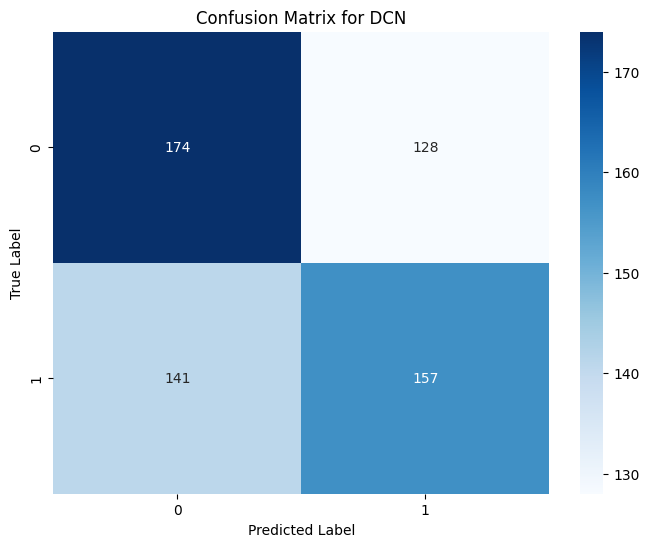

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Make predictions on the test set
y_pred_proba = best_model.predict(X_test)
y_pred_single_label = np.argmax(y_pred_proba, axis=1)
y_true_single_label = np.argmax(y_test, axis=1)

# Compute the confusion matrix
cm = confusion_matrix(y_true_single_label, y_pred_single_label)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y_true_single_label), # Assumes labels are 0, 1, ...
            yticklabels=np.unique(y_true_single_label))
plt.title(f'Confusion Matrix for {best_model_name}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()